In [1]:
# Praktikum 6 : Clustering K-Means, DBSCAN & AHC

**Mata kuliah** : Rekayasa dan Penambangan Data — Informatika UAD 2026
**Dataset** : `dataAlumni.xlsx`
**Fitur clustering** : `IPK` dan `Masa Studi`

---
## 1. Import Library & Baca Dataset

Colab: file sudah diupload ke `/content` atau link ke Drive. Ganti `'......'` dengan path file `dataAlumni.xlsx` milikmu.

SyntaxError: invalid character '—' (U+2014) (832938958.py, line 3)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.metrics import silhouette_samples, silhouette_score

# Upload / muat dataset
# (di Colab bisa pakai : from google.colab import files; files.upload())
df = pd.read_excel('/content/dataAlumni.xlsx')
df

,No,Nim,Nama,Tempat & tanggal lahir,Fakultas/Ketrampilan,Alamat,Tahun Masuk,Tahun Lulus,Status Pekerjaan,Lama Masa Tunggu (bulan),Gaji Pertama bekerjaa,Nilai Toefl,IPK,Masa Studi
0,1,9018263,Puguh Drajat E.P,"Purworejo, 4 November 1989",FTI/ Teknik Infomatika,Tangerang Rt. 01/ 0,2009,2016,PNS,24,1475635,390,2.13,7
1,2,12022030,Arsyad Cahya Subrata,"Bantul, 21 juni 1994",FTI / Teknik Elektro,"Karangpule Rt.01 , Tirtonirmolo , Kasihan Bantul",2012,2016,Swasta,6,1000000,456,3.80,4
2,3,12020021,Yesi Novela,"Tempilang, 1 januari 1995",FTI,"Semaki, Umbulharjo",2012,2016,Mahasiswa,24,1475635,508,3.50,4
3,4,9018269,Pandu Herwijaya,"Lampung, 19 Desember 1990",FTI/ Teknik Infomatika,"Tamantirto, Kasihan ,Bantul",2009,2016,Wiraswasta,24,1475634,413,2.75,7
4,5,9018109,Anjar Prasetyo,"Gunungkidul, 27 April 1991",FTI /Teknik Informatika,"Umbulharjo , Yogyakarta",2009,2016,Petani,8,1340000,484,3.70,7
5,6,9020026,Moh. Dadi Kurniawan,"Savanajaya, 27 Maret 1992",FTI / Futsal,Saren Rt. 02 Rw. 01 Caturtunggal,2009,2016,Peternak,24,1475635,400,3.24,7
6,7,12018060,Martin Sarlina,"Lepak, 23 Maret 1994",FTI,NTB,2012,2016,Wiraswasta,24,1475635,396,3.27,4
7,8,11018022,Yan Adhi Permadi,"Jepara, 22 juni 1993",FTI,Umbulharjo V,2011,2016,Wiraswasta,24,1475635,460,3.20,5
8,9,9018212,Achicha Wahyuni,"Yogyakarta, 3 juni 1991",FTI/ Web Design,"Noyokerten, Sendangirto, Berbah",2009,2016,Guru,0,600000,403,3.24,7
9,10,9018301,Yayan Tisna Permadi,"Purbalingga, 08 Oktober 1991",FTI/ Teknik Infomatika,"Tajug, Rt.04/ 05 Purbalingga",2009,2016,Teknisi,24,1475635,450,3.06,7


In [3]:
# Melihat informasi singkat data
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   No                        16 non-null     int64  
 1   Nim                       16 non-null     int64  
 2   Nama                      16 non-null     object 
 3   Tempat & tanggal lahir    16 non-null     object 
 4   Fakultas/Ketrampilan      16 non-null     object 
 5   Alamat                    16 non-null     object 
 6   Tahun Masuk               16 non-null     int64  
 7   Tahun Lulus               16 non-null     int64  
 8   Status Pekerjaan          16 non-null     object 
 9   Lama Masa Tunggu (bulan)  16 non-null     int64  
 10  Gaji Pertama bekerjaa     16 non-null     int64  
 11  Nilai Toefl               16 non-null     int64  
 12  IPK                       16 non-null     float64
 13  Masa Studi                16 non-null     int64  
dtypes: float64(1

,No,Nim,Tahun Masuk,Tahun Lulus,Lama Masa Tunggu (bulan),Gaji Pertama bekerjaa,Nilai Toefl,IPK,Masa Studi
count,16.000000,1.600000e+01,16.000000,16.0,16.000000,1.600000e+01,16.000000,16.000000,16.000000
mean,8.500000,1.058168e+07,2010.562500,2016.0,17.437500,1.321647e+06,431.562500,3.251875,5.437500
std,4.760952,1.459942e+06,1.459166,0.0,10.236984,2.869470e+05,36.491038,0.408529,1.459166
min,1.000000,9.018109e+06,2009.000000,2016.0,0.000000,6.000000e+05,390.000000,2.130000,4.000000
25%,4.750000,9.018268e+06,2009.000000,2016.0,7.500000,1.305000e+06,402.250000,3.120000,4.000000
50%,8.500000,1.101807e+07,2011.000000,2016.0,24.000000,1.475635e+06,418.000000,3.255000,5.000000
75%,12.250000,1.201928e+07,2012.000000,2016.0,24.000000,1.475635e+06,457.000000,3.525000,7.000000
max,16.000000,1.202204e+07,2012.000000,2016.0,24.000000,1.500000e+06,508.000000,3.800000,7.000000


In [ ]:
## 2. Seleksi Kolom & Persiapan Data

Pilih kolom yang dibutuhkan untuk menghitung fitur clustering
(`IPK` dan `Masa Studi`); kolom lain (No, Nama, Alamat, dll) tidak
digunakan.

Catatan: bila kolom `Masa Studi` belum tersedia di datasetmu,
hitung dulu `Masa Studi` = `Tahun Lulus` - `Tahun Masuk`.

In [5]:
# Pilih kolom yang diperlukan
d = df[['Nim', 'IPK', 'Tahun Masuk', 'Tahun Lulus']].copy()

# Buang baris kosong SEBELUM menghitung Masa Studi,
# agar selisih dua nilai NaN tidak menghasilkan error/junk
d = d.dropna(axis=0, how='any')

# Perbarui nama kolom bila perlu, agar sesuai dengan nama fitur
d.columns = ['NIM', 'IPK', 'TAHUN MASUK', 'TAHUN LULUS']

# Hitung masa studi
d['Masa Studi'] = d['TAHUN LULUS'] - d['TAHUN MASUK']

d

,NIM,IPK,TAHUN MASUK,TAHUN LULUS,Masa Studi
0,9018263,2.13,2009,2016,7
1,12022030,3.80,2012,2016,4
2,12020021,3.50,2012,2016,4
3,9018269,2.75,2009,2016,7
4,9018109,3.70,2009,2016,7
5,9020026,3.24,2009,2016,7
6,12018060,3.27,2012,2016,4
7,11018022,3.20,2011,2016,5
8,9018212,3.24,2009,2016,7
9,9018301,3.06,2009,2016,7


In [6]:
# Cek tipe data
print(d.dtypes)

NIM              int64
IPK            float64
TAHUN MASUK      int64
TAHUN LULUS      int64
Masa Studi       int64
dtype: object


In [ ]:
## 3. Proses Clustering

Ambil data `IPK` dan `Masa Studi` yang akan di-clustering,
ubah index agar mulai dari 0, konversi ke format matrix (`.values`).

In [7]:
# Ubah index dataframe agar lebih memudahkan dalam melakukan clustering
dTable = d[['IPK', 'Masa Studi']].reset_index(drop=True)
dTable

,IPK,Masa Studi
0,2.13,7
1,3.80,4
2,3.50,4
3,2.75,7
4,3.70,7
5,3.24,7
6,3.27,4
7,3.20,5
8,3.24,7
9,3.06,7


In [8]:
# Ambil data IPK dan Masa Studi untuk dilakukan clustering
X = dTable[['IPK', 'Masa Studi']].values
X.shape

(16, 2)

In [ ]:
### 3a. K-Means

Tentukan jumlah cluster (contoh: 3). Plot hasil cluster dengan label
index data, dan tandai centroid dengan marker `'x'`.

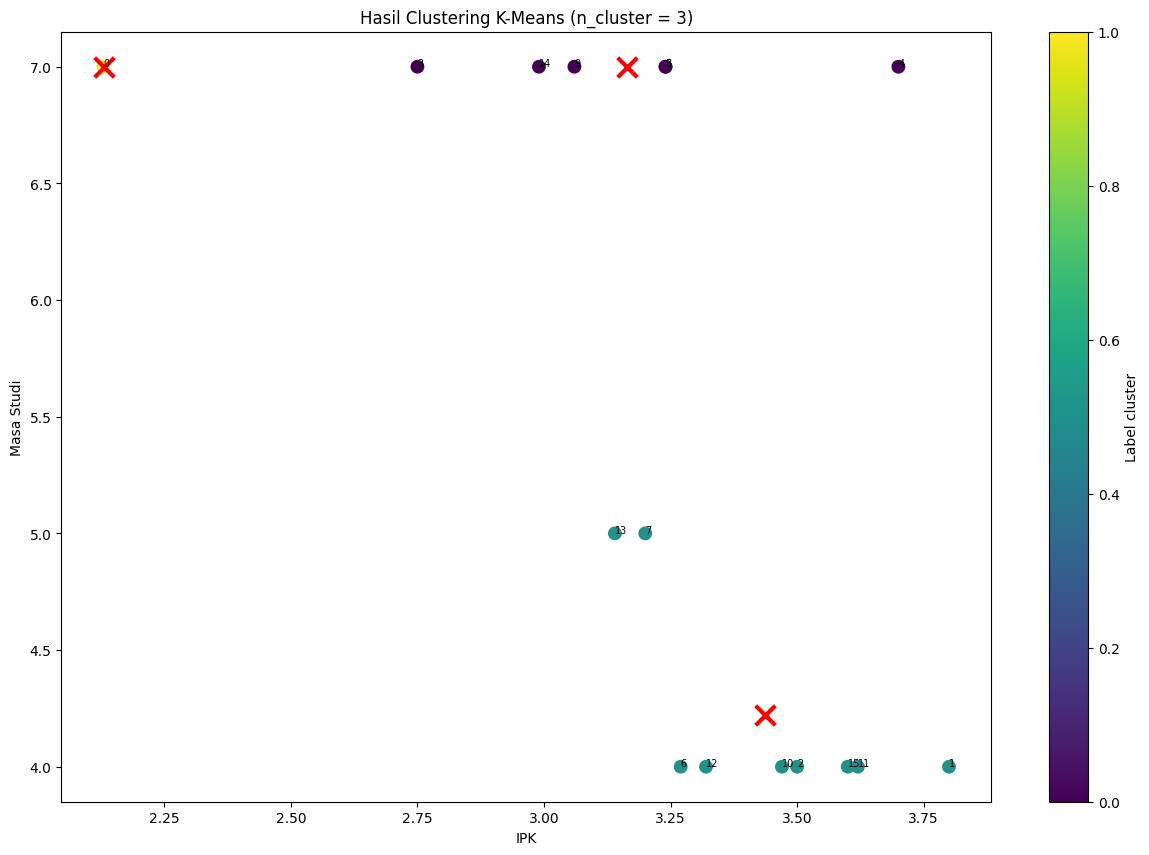

In [9]:
# K-Means, n_cluster = 3
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X)

centroids = kmeans.cluster_centers_
labels = kmeans.labels_

plt.figure(figsize=(15, 10))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=80)
for i in range(len(X)):
    plt.text(X[i][0], X[i][1], '%s' % (i), fontsize=7)

plt.scatter(centroids[:, 0], centroids[:, 1], marker='x', s=200, c='red', linewidths=3)
plt.xlabel('IPK')
plt.ylabel('Masa Studi')
plt.title('Hasil Clustering K-Means (n_cluster = 3)')
plt.colorbar(label='Label cluster')
plt.show()

In [ ]:
### 3b. DBSCAN

DBSCAN **tidak perlu menentukan jumlah cluster di awal**.
Gunakan parameter `eps` (radius) dan `min_samples` (minimum tetangga).
Label `-1` menandakan noise/outlier.

Jumlah titik noise (label -1): 3


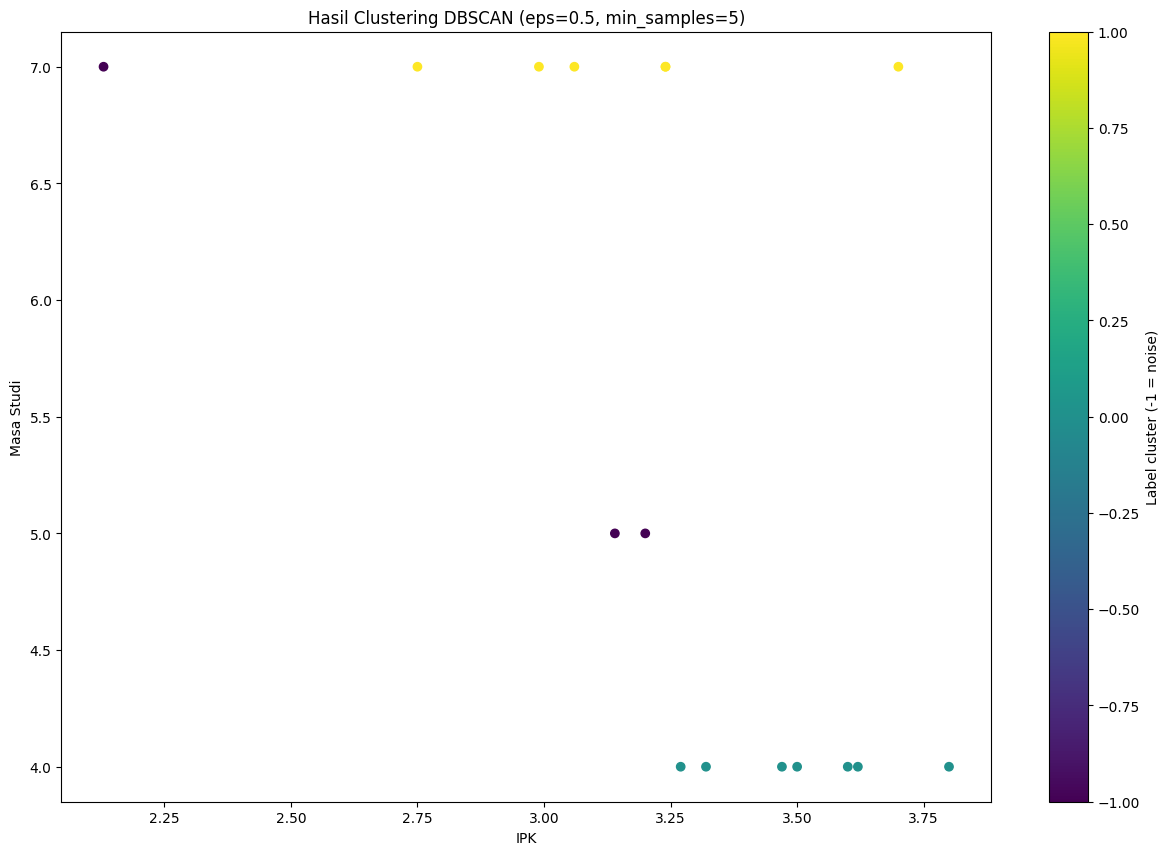

In [10]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan.fit(X)
labels_dbscan = dbscan.labels_   # -1 = noise

n_noise = int(np.sum(labels_dbscan == -1))
print('Jumlah titik noise (label -1):', n_noise)

plt.figure(figsize=(15, 10))
plt.scatter(X[:, 0], X[:, 1], c=labels_dbscan, cmap='viridis')
plt.title('Hasil Clustering DBSCAN (eps=0.5, min_samples=5)')
plt.xlabel('IPK')
plt.ylabel('Masa Studi')
plt.colorbar(label='Label cluster (-1 = noise)')
plt.show()

In [ ]:
### 3c. AHC (Agglomerative Hierarchical Clustering)

Sebelum menentukan jumlah cluster, tampilkan dulu **dendrogram**
untuk melihat struktur hierarki penggabungan cluster, lalu potong
dendrogram sehingga terbentuk n cluster yang diinginkan.

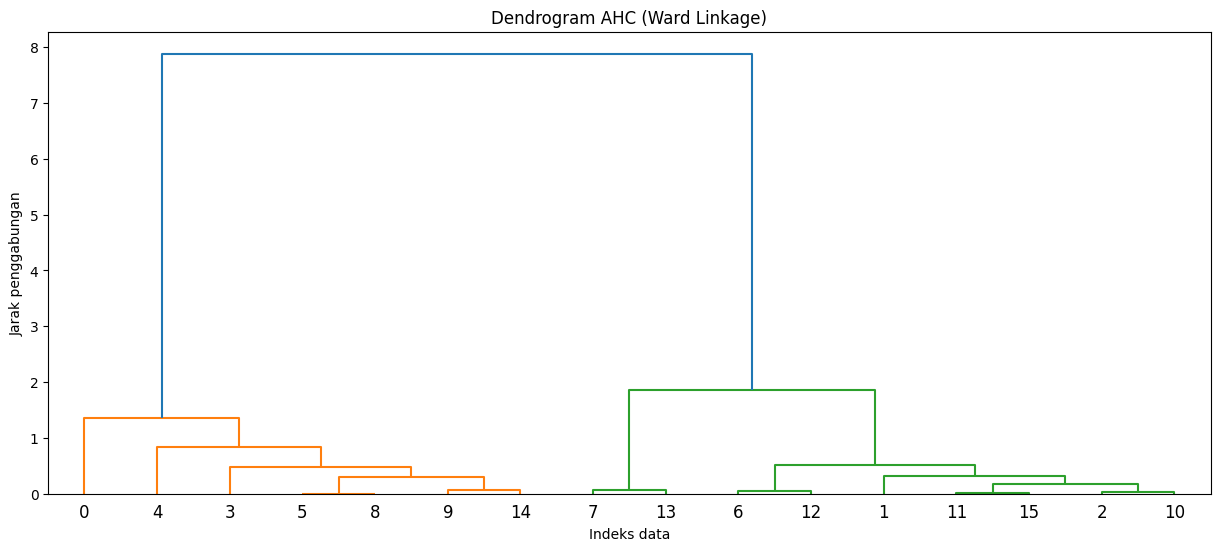

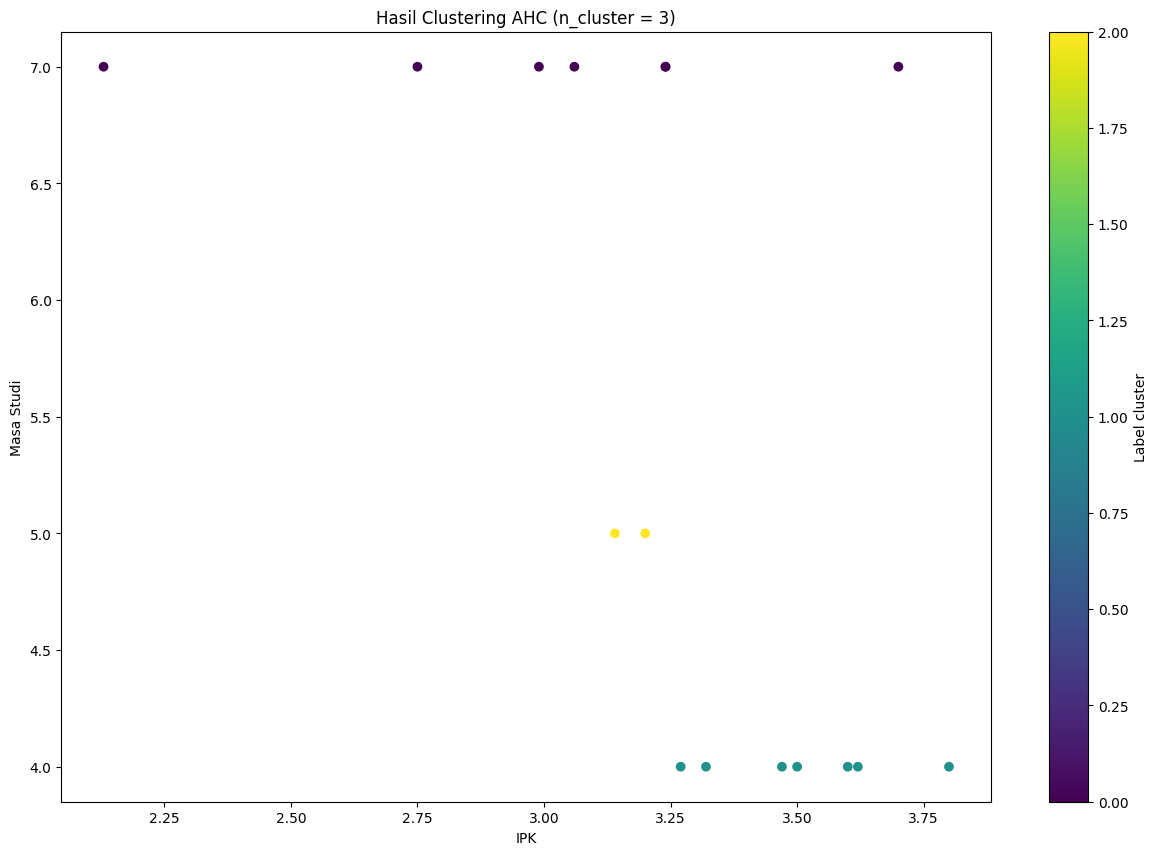

In [11]:
from scipy.cluster.hierarchy import dendrogram, linkage

Z = linkage(X, method='ward')
plt.figure(figsize=(15, 6))
dendrogram(Z, labels=range(len(X)))
plt.title('Dendrogram AHC (Ward Linkage)')
plt.xlabel('Indeks data')
plt.ylabel('Jarak penggabungan')
plt.show()

# Potong dendrogram sehingga terbentuk 3 cluster
agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels_ahc = agg.fit_predict(X)

plt.figure(figsize=(15, 10))
plt.scatter(X[:, 0], X[:, 1], c=labels_ahc, cmap='viridis')
plt.title('Hasil Clustering AHC (n_cluster = 3)')
plt.xlabel('IPK')
plt.ylabel('Masa Studi')
plt.colorbar(label='Label cluster')
plt.show()

In [ ]:
## 4. Pengujian Silhouette & Purity

Silhouette diuji untuk rentang jumlah cluster `range_n_clusters = [2,3,4,5,6]`.
Pilih jumlah cluster dengan nilai rata-rata silhouette **tertinggi**.
Khusus DBSCAN, keluarkan dulu titik berlabel `-1` (noise) sebelum pengujian.

For n_clusters = 2 The average silhouette_score is: 0.7950515205884209


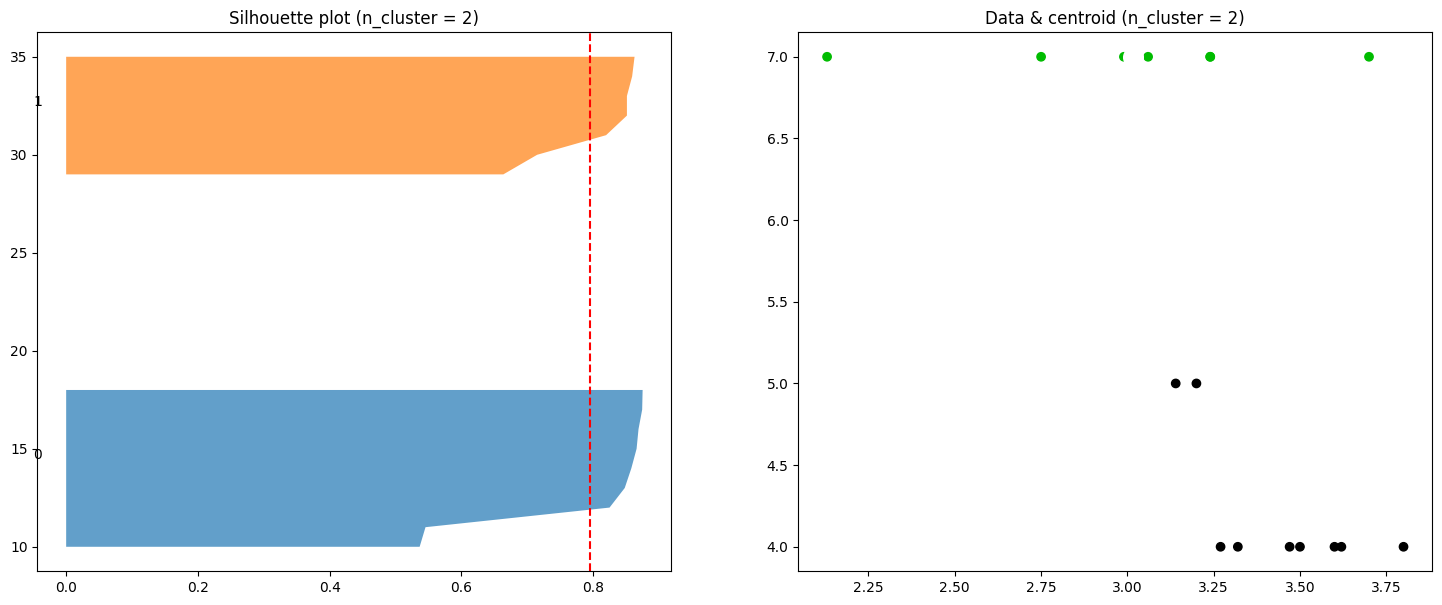

For n_clusters = 3 The average silhouette_score is: 0.7838693708424312


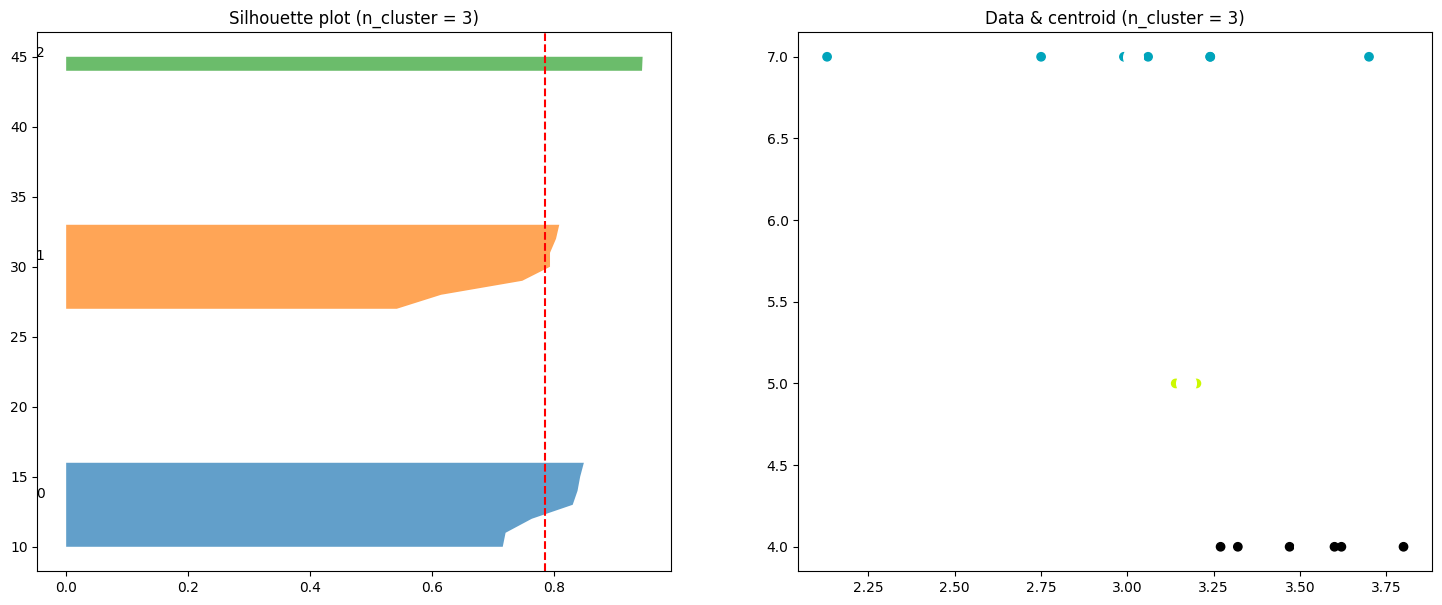

For n_clusters = 4 The average silhouette_score is: 0.6928453893135753


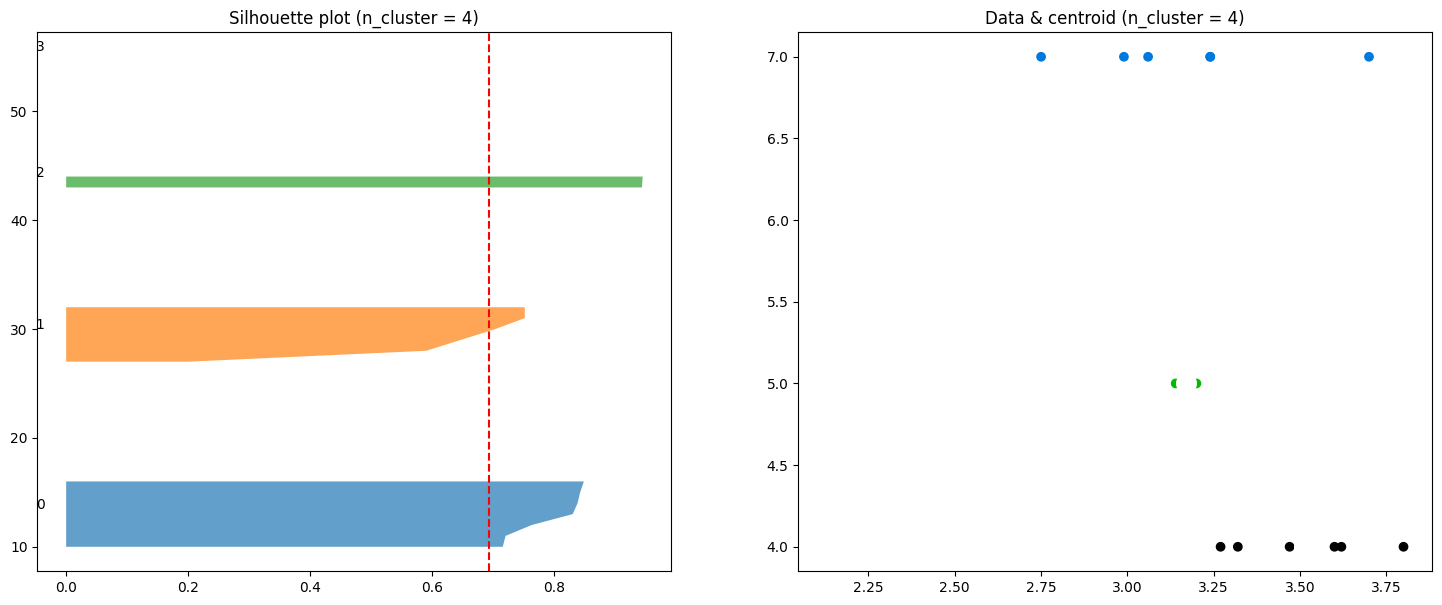

For n_clusters = 5 The average silhouette_score is: 0.6407542452051153


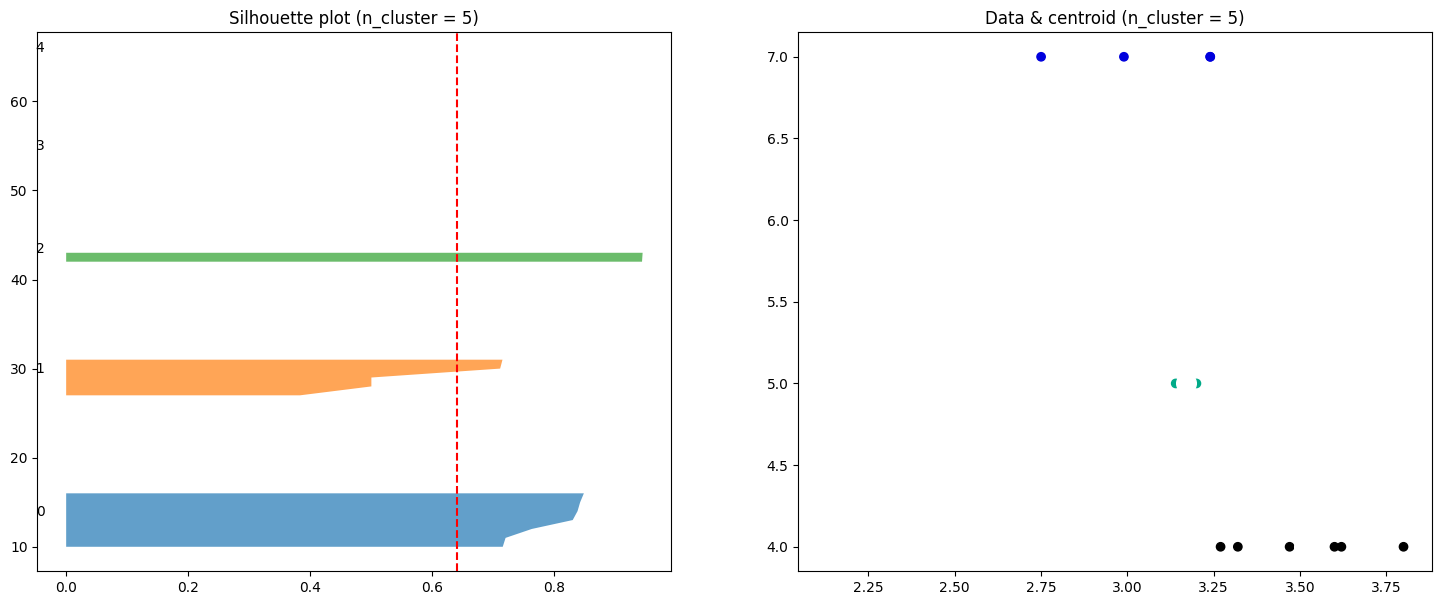

For n_clusters = 6 The average silhouette_score is: 0.5338812626652314


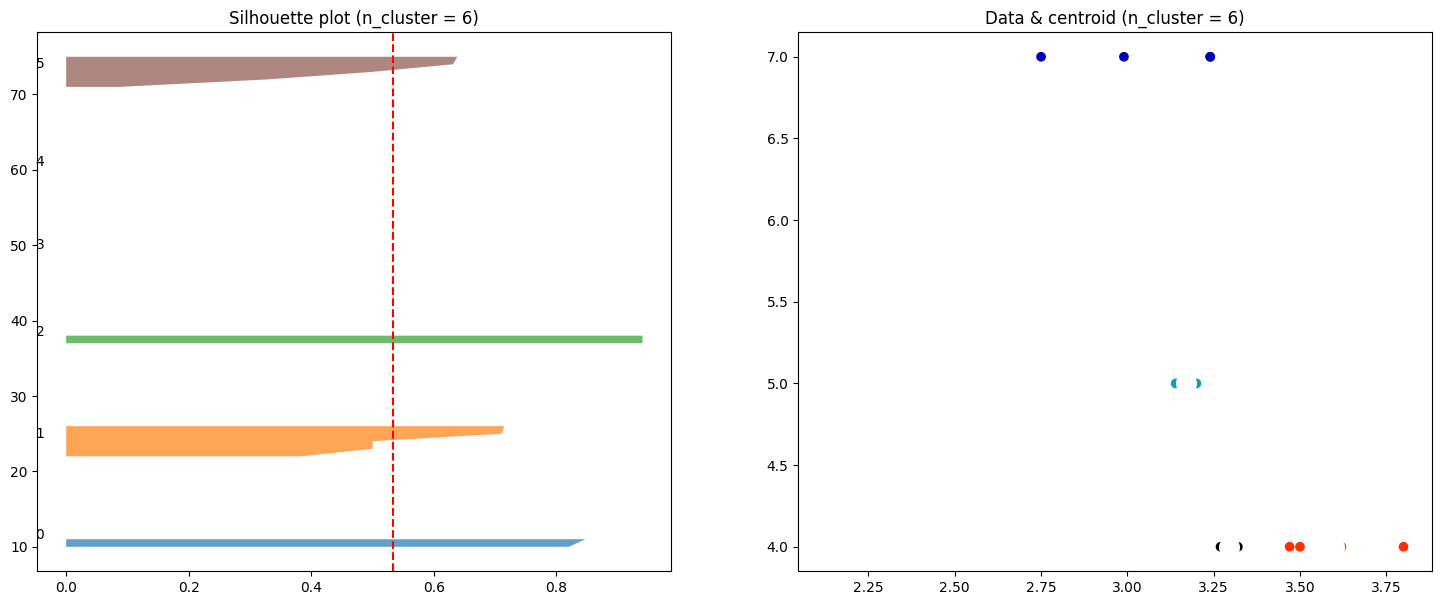

In [12]:
def silhouette_test(X, range_n_clusters):
    for n_clusters in range_n_clusters:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))
        clusterer = KMeans(n_clusters=n_clusters, random_state=10)
        cluster_labels = clusterer.fit_predict(X)

        silhouette_avg = silhouette_score(X, cluster_labels)
        print('For n_clusters =', n_clusters,
              'The average silhouette_score is:', silhouette_avg)

        sample_silhouette_values = silhouette_samples(X, cluster_labels)
        y_lower = 10
        for i in range(n_clusters):
            ith = np.sort(sample_silhouette_values[cluster_labels == i])
            size = ith.shape[0]
            y_upper = y_lower + size
            ax1.fill_betweenx(np.arange(y_lower, y_upper),
                              0, ith, alpha=0.7)
            ax1.text(-0.05, y_lower + 0.5 * size, str(i))
            y_lower = y_upper + 10
        ax1.set_title('Silhouette plot (n_cluster = %d)' % n_clusters)
        ax1.axvline(x=silhouette_avg, color='red', linestyle='--')

        colors = plt.cm.nipy_spectral(cluster_labels.astype(float) / n_clusters)
        ax2.scatter(X[:, 0], X[:, 1], c=colors)
        centers = clusterer.cluster_centers_
        ax2.scatter(centers[:, 0], centers[:, 1], marker='o', c='white', s=200)
        ax2.set_title('Data & centroid (n_cluster = %d)' % n_clusters)
        plt.show()

range_n_clusters = [2, 3, 4, 5, 6]
silhouette_test(X, range_n_clusters)

# -> JUMLAH cluster terbaik (nilai silhouette tertinggi) = ?

In [13]:
# Silhouette untuk DBSCAN (keluarkan dulu titik noise, label -1)
mask = labels_dbscan != -1
X_dbscan = X[mask]
labels_dbscan_clean = labels_dbscan[mask]

if len(set(labels_dbscan_clean)) > 1:
    print('Silhouette DBSCAN (tanpa noise):', silhouette_score(X_dbscan, labels_dbscan_clean))
else:
    print('Tidak bisa menghitung silhouette DBSCAN: hanya ada 1 cluster atau 0 titik tersisa setelah noise dikeluarkan.')

Silhouette DBSCAN (tanpa noise): 0.9033764418210818


In [ ]:
# Rumus Purity

Purity dipakai untuk mengukur kemurnian suatu hasil clustering
(bila dataset memiliki ground-truth label/kelas, misal kelas
`LamaTunggu`). Jika dataset tidak punya label, purity bisa dipakai
untuk membandingkan hasil antar-algoritma terhadap satu label
referensi (misal hasil K-Means dipakai sebagai acuan).

In [ ]:
def purity_score(cluster, classes):
    cluster = np.array(cluster)
    classes = np.array(classes)
    total = 0
    for cl in set(cluster):
        idx = np.where(cluster == cl)[0]
        total += np.max(np.bincount(classes[idx]))
    return total / len(cluster)

# Contoh: pakai label K-Means sebagai acuan, bandingkan dengan label AHC
purity_ahc_dgn_kmeans = purity_score(labels_ahc, labels)
print('Purity AHC terhadap label KMeans :', purity_ahc_dgn_kmeans)

# (opsional) bandingkan DBSCAN (tanpa noise) terhadap label K-Means
mask = labels_dbscan != -1
purity_dbscan_dgn_kmeans = purity_score(labels_dbscan[mask], labels[mask])
print('Purity DBSCAN (tanpa noise) terhadap label KMeans :', purity_dbscan_dgn_kmeans)

In [ ]:
## 5. Analisis Hasil

Berdasarkan data `dataAlumni.xlsx` (16 baris, fitur `IPK` & `Masa Studi`):

1. **K-Means** : silhouette tertinggi pada `k = 2` (0.7951).
   Urutan: k=2 → 0.7951, k=3 → 0.7839, k=4 → 0.6928, k=5 → 0.6408, k=6 → 0.5339.
   **Jawaban: 2 cluster terbaik**, meskipun 3 cluster masih layak (0.7839).

2. **DBSCAN (eps=0.5, min_samples=5)** : **3 titik noise** (label -1) dari 16 total.
   Silhouette setelah noise dikeluarkan = **0.9034** (sangat rapat).
   DBSCAN dengan parameter ini cenderung menganggap sebagian data sebagai outlier
   karena `min_samples=5` relatif besar untuk dataset 16 baris.

3. **AHC (n=3, Ward)** : 3 cluster terbentuk (label 0, 1, 2).
   Purity AHC terhadap label KMeans(3) = **0.9375** — sangat sejalan.
   Purity DBSCAN (tanpa noise) terhadap KMeans(3) = **1.0**.

4. **Algoritma paling sesuai : K-Means dengan k=2 atau k=3.**
   K-Means stabil dan silhouette-nya tetap tinggi hingga k=4.
   DBSCAN kurang sesuai karena `min_samples` sulit dipilih secara otomatis
   untuk dataset kecil (16 baris) — angka yang sama berubah drastis
   tergantung `eps` dan `min_samples`.
   AHC sangat cocok karena dendrogram memperlihatkan struktur hierarki
   yang jelas dan purity-nya hampir identik dengan K-Means.

## **POST TEST**
1. Gunakan Kolom IPK dengan Nilai TOEFL
2. Ubah konfigurasi DBSCN pada praktikum menjadi eps = 1.0 dan min_samples = 3, lalu tampilkan jumlah titik noise, jumlah cluster yang tersebtnuk, dan nilai silhouette-nya!
3. Ubah konfigurasi AHC pada praktikum menjadi n_clusters = 4 lalu tampilkan jumlah cluster dan label tiap baris!

1. Gunakan Kolom IPK dengan Nilai TOEFL

In [16]:
# Pilih kolom yang diperlukan
a = df[['Nim', 'IPK', 'Nilai Toefl']].copy()

# Buang baris kosong SEBELUM menghitung Masa Studi,
# agar selisih dua nilai NaN tidak menghasilkan error/junk
a = a.dropna(axis=0, how='any')

a

,Nim,IPK,Nilai Toefl
0,9018263,2.13,390
1,12022030,3.80,456
2,12020021,3.50,508
3,9018269,2.75,413
4,9018109,3.70,484
5,9020026,3.24,400
6,12018060,3.27,396
7,11018022,3.20,460
8,9018212,3.24,403
9,9018301,3.06,450


Ubah konfigurasi DBSCN pada praktikum menjadi eps = 1.0 dan min_samples = 3, lalu tampilkan jumlah titik noise, jumlah cluster yang tersebtnuk, dan nilai silhouette-nya!

In [20]:
# Ubah index dataframe agar lebih memudahkan dalam melakukan clustering
aTable = a[['IPK', 'Nilai Toefl']].reset_index(drop=True)
aTable

,IPK,Nilai Toefl
0,2.13,390
1,3.80,456
2,3.50,508
3,2.75,413
4,3.70,484
5,3.24,400
6,3.27,396
7,3.20,460
8,3.24,403
9,3.06,450


In [21]:
X = aTable[['IPK', 'Nilai Toefl']].values
X.shape

(16, 2)

Jumlah titik noise (label -1): 10


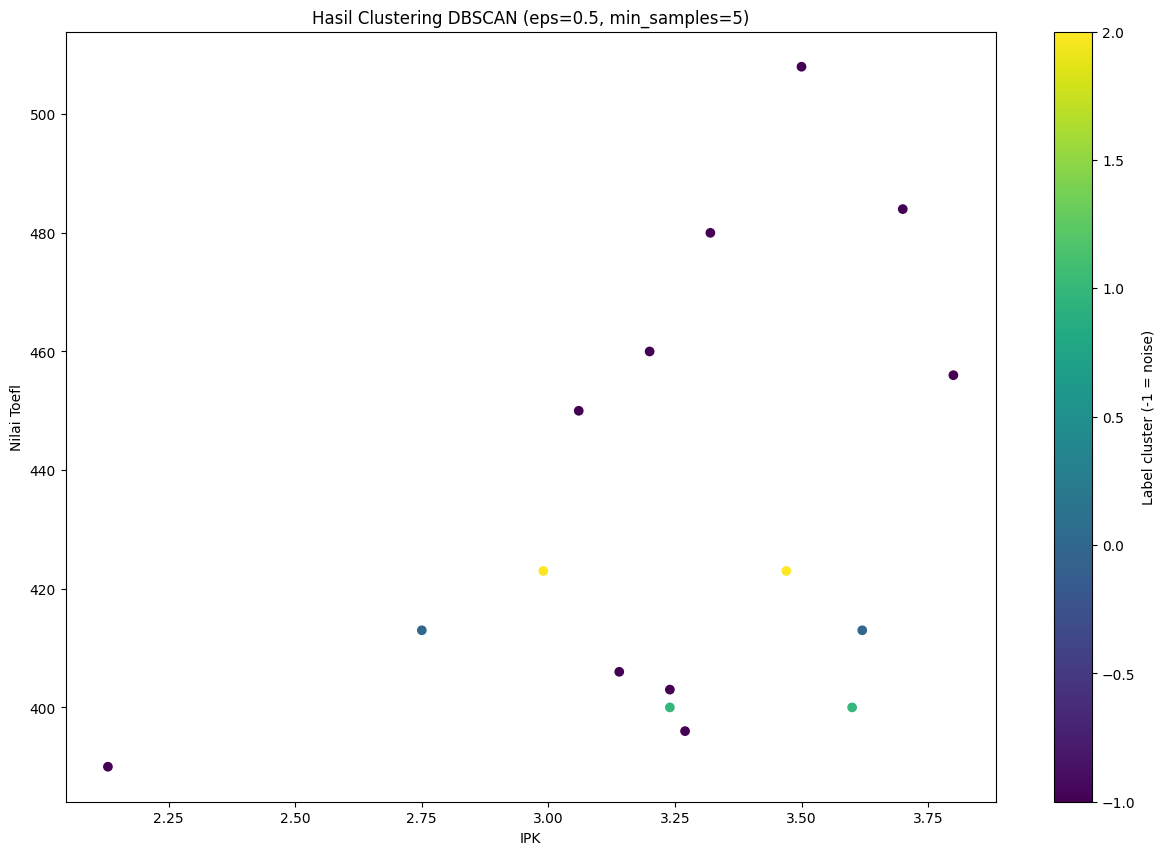

In [23]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=1.0, min_samples=2)
dbscan.fit(X)
labels_dbscan = dbscan.labels_   # -1 = noise

n_noise = int(np.sum(labels_dbscan == -1))
print('Jumlah titik noise (label -1):', n_noise)

plt.figure(figsize=(15, 10))
plt.scatter(X[:, 0], X[:, 1], c=labels_dbscan, cmap='viridis')
plt.title('Hasil Clustering DBSCAN (eps=0.5, min_samples=5)')
plt.xlabel('IPK')
plt.ylabel('Nilai Toefl')
plt.colorbar(label='Label cluster (-1 = noise)')
plt.show()

In [26]:
# Silhouette untuk DBSCAN (keluarkan dulu titik noise, label -1)
mask = labels_dbscan != -1
X_dbscan = X[mask]
labels_dbscan_clean = labels_dbscan[mask]

if len(set(labels_dbscan_clean)) > 1:
    print('Silhouette DBSCAN (tanpa noise):', silhouette_score(X_dbscan, labels_dbscan_clean))
else:
    print('Tidak bisa menghitung silhouette DBSCAN: hanya ada 1 cluster atau 0 titik tersisa setelah noise dikeluarkan.')

Silhouette DBSCAN (tanpa noise): 0.9458326389191732


3. Ubah konfigurasi AHC pada praktikum menjadi n_clusters = 4 lalu tampilkan jumlah cluster dan label tiap baris!

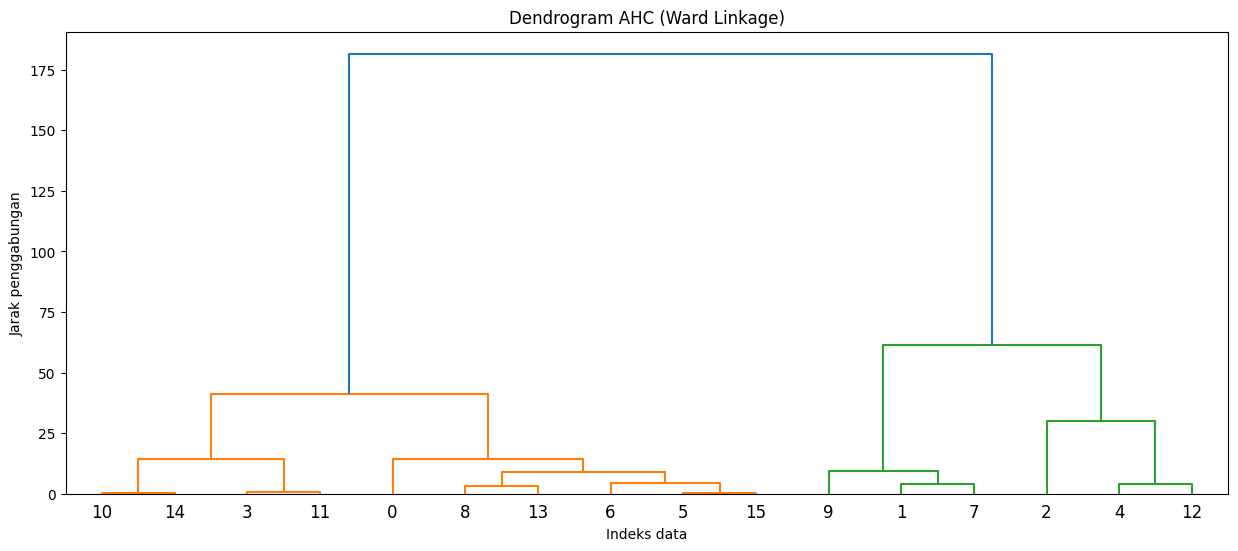

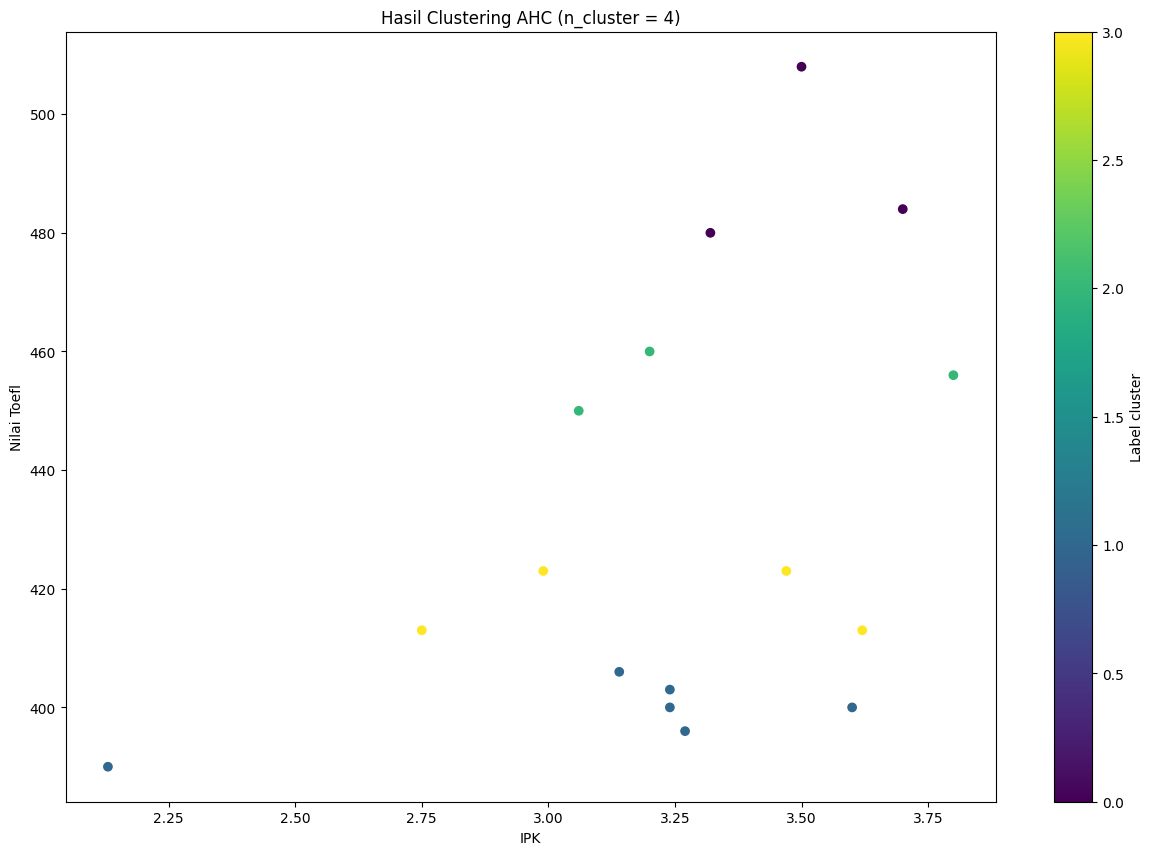

In [29]:
from scipy.cluster.hierarchy import dendrogram, linkage

Z = linkage(X, method='ward')
plt.figure(figsize=(15, 6))
dendrogram(Z, labels=range(len(X)))
plt.title('Dendrogram AHC (Ward Linkage)')
plt.xlabel('Indeks data')
plt.ylabel('Jarak penggabungan')
plt.show()

# Potong dendrogram sehingga terbentuk 3 cluster
agg = AgglomerativeClustering(n_clusters=4, linkage='ward')
labels_ahc = agg.fit_predict(X)

plt.figure(figsize=(15, 10))
plt.scatter(X[:, 0], X[:, 1], c=labels_ahc, cmap='viridis')
plt.title('Hasil Clustering AHC (n_cluster = 4)')
plt.xlabel('IPK')
plt.ylabel('Nilai Toefl')
plt.colorbar(label='Label cluster')
plt.show()